# Lead Conversion Prediction — Logistic Regression
**Intern: A. Sai Akhil | Project 2 of 2 | 10-Day Internship Prototype**

Estimates the probability that a lead converts within 30 days, using engagement features
measured **before** the 30-day outcome window closes. This notebook walks through all 20
steps of the workflow, end to end, on the **raw**, uncleaned dataset
(`data/lead_conversion_raw.csv`).

## 1. Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/lead_conversion_raw.csv", parse_dates=["lead_created_date"])
print(f"Loaded raw data: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Loaded raw data: 20200 rows, 7 columns

## 2. Data Understanding

In [2]:
print("Column dtypes:")
print(df.dtypes)

Column dtypes:
lead_id                                    str
lead_created_date               datetime64[us]
channel                                    str
product_interest                           str
prior_website_visits                   float64
prior_email_engagement_count           float64
converted_30d                            int64
dtype: object

In [3]:
df.describe(include="all").T

In [4]:
print("Target balance (converted_30d):")
print(df["converted_30d"].value_counts(normalize=True))
print("\nMissing value counts:")
print(df.isna().sum())

Target balance (converted_30d):
converted_30d
0    0.576584
1    0.423416
Name: proportion, dtype: float64

Missing value counts:
lead_id                           0
lead_created_date                 0
channel                         505
product_interest                404
prior_website_visits            501
prior_email_engagement_count    601
converted_30d                     0
dtype: int64

## 3. Exploratory Data Analysis (EDA)

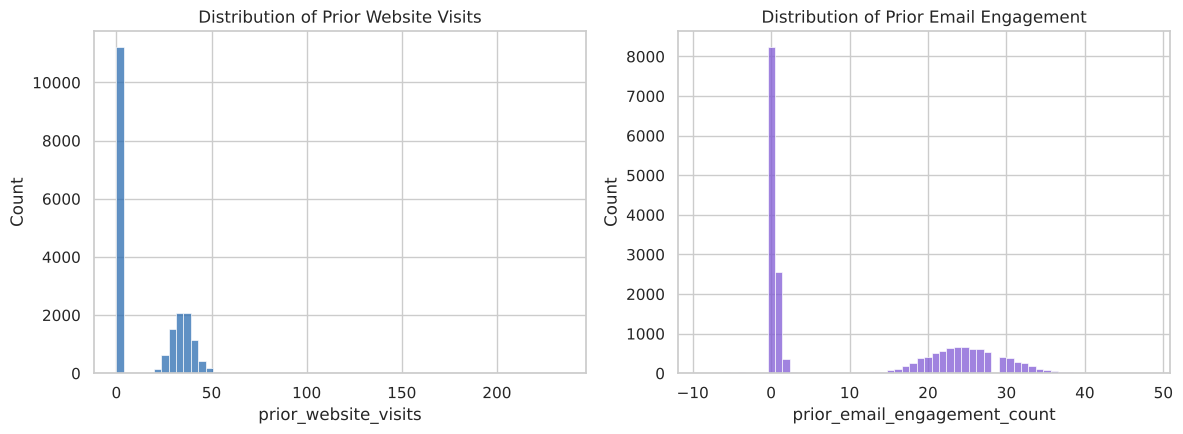

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df["prior_website_visits"].dropna(), bins=60, ax=axes[0], color="#2b6cb0")
axes[0].set_title("Distribution of Prior Website Visits")
sns.histplot(df["prior_email_engagement_count"].dropna(), bins=60, ax=axes[1], color="#805ad5")
axes[1].set_title("Distribution of Prior Email Engagement")
plt.tight_layout()
plt.show()

Mean visits/email by conversion outcome:
               prior_website_visits  prior_email_engagement_count
converted_30d                                                    
0                          2.150955                      0.269500
1                         36.686256                     24.720737

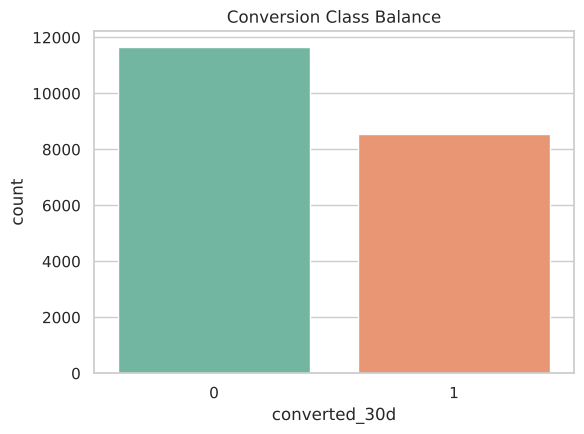

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(x="converted_30d", data=df, ax=ax, palette="Set2")
ax.set_title("Conversion Class Balance")
plt.tight_layout()
plt.show()

print("Mean visits/email by conversion outcome:")
print(df.groupby("converted_30d")[["prior_website_visits", "prior_email_engagement_count"]].mean())

## 4. Data Cleaning
The raw data contains duplicate leads, inconsistent channel/product text, and some
invalid negative email-engagement counts (data-entry errors).

In [7]:
before = len(df)
df = df.drop_duplicates(subset=["lead_id"]).copy()
print(f"Removed {before - len(df)} duplicate rows (by lead_id)")

df["channel"] = df["channel"].astype(str).str.strip().str.title()
df["channel"] = df["channel"].replace({
    "Social Media": "Social", "Paid Search": "Search", "E-Mail": "Email", "Nan": np.nan
})
df["product_interest"] = df["product_interest"].astype(str).str.strip().str.title()
df["product_interest"] = df["product_interest"].replace({"Add On": "Add-on", "Nan": np.nan})

neg_mask = df["prior_email_engagement_count"] < 0
print(f"Found {neg_mask.sum()} invalid negative engagement values -> set to missing")
df.loc[neg_mask, "prior_email_engagement_count"] = np.nan

print("\nCleaned channel value counts:")
print(df["channel"].value_counts(dropna=False))

Removed 200 duplicate rows (by lead_id)
Found 160 invalid negative engagement values -> set to missing

Cleaned channel value counts:
channel
Social       5783
Search       4854
Email        3823
Display      3044
Affiliate    1996
NaN           500
Name: count, dtype: int64

## 5. Handling Missing Values
Rows with any missing required value are **dropped** rather than imputed, so training
only ever sees genuinely observed lead data.

In [8]:
print("Missing values before handling:")
print(df.isna().sum())

before = len(df)
df = df.dropna().copy()
print(f"\nDropped {before - len(df)} rows containing missing values -> {len(df)} rows remain")

Missing values before handling:
lead_id                           0
lead_created_date                 0
channel                         500
product_interest                400
prior_website_visits            500
prior_email_engagement_count    754
converted_30d                     0
dtype: int64

Dropped 2058 rows containing missing values -> 17942 rows remain

## 6. Handling Outliers
Extreme `prior_website_visits` values above the 99.5th percentile (injected tracking
errors) are removed.

In [9]:
before = len(df)
cap = df["prior_website_visits"].quantile(0.995)
mask = df["prior_website_visits"] <= cap
removed = (~mask).sum()
df = df[mask].reset_index(drop=True)
print(f"prior_website_visits: removed {removed} extreme outliers above the 99.5th percentile ({cap:.0f})")
print(f"Rows remaining after outlier removal: {len(df)} (from {before})")

prior_website_visits: removed 89 extreme outliers above the 99.5th percentile (167)
Rows remaining after outlier removal: 17853 (from 17942)

## 7. Feature Selection

In [10]:
candidate_features = ["channel", "product_interest", "prior_website_visits", "prior_email_engagement_count"]
numeric = ["prior_website_visits", "prior_email_engagement_count"]
corr = df[numeric + ["converted_30d"]].corr()["converted_30d"].drop("converted_30d")
print("Correlation of numeric candidates with converted_30d:")
print(corr.sort_values(ascending=False))
print(f"\nSelected features: {candidate_features}")

Correlation of numeric candidates with converted_30d:
prior_email_engagement_count    0.965933
prior_website_visits            0.839972
Name: converted_30d, dtype: float64

Selected features: ['channel', 'product_interest', 'prior_website_visits', 'prior_email_engagement_count']

## 8. Feature Engineering
Two derived features are added: total engagement and the email-to-visit engagement ratio.

In [11]:
df["total_engagement"] = df["prior_website_visits"] + df["prior_email_engagement_count"]
df["engagement_ratio"] = df["prior_email_engagement_count"] / df["prior_website_visits"].replace(0, np.nan)
df["engagement_ratio"] = df["engagement_ratio"].fillna(0)
print("Engineered features added: total_engagement, engagement_ratio")
df[["total_engagement", "engagement_ratio"]].describe()

Engineered features added: total_engagement, engagement_ratio

## 9. Data Preprocessing

In [12]:
numeric_features = ["prior_website_visits", "prior_email_engagement_count", "total_engagement", "engagement_ratio"]
categorical_features = ["channel", "product_interest"]
feature_cols = numeric_features + categorical_features
target_col = "converted_30d"

df.to_csv("../data/lead_conversion_clean.csv", index=False)
print(f"Cleaned dataset saved: {df.shape[0]} rows -> ../data/lead_conversion_clean.csv")
print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

Cleaned dataset saved: 17853 rows -> ../data/lead_conversion_clean.csv
Numeric features: ['prior_website_visits', 'prior_email_engagement_count', 'total_engagement', 'engagement_ratio']
Categorical features: ['channel', 'product_interest']

## 10. Encoding Categorical Variables
`channel` and `product_interest` are one-hot encoded, with `handle_unknown="ignore"` to
protect inference against unseen categories.

In [13]:
from sklearn.preprocessing import OneHotEncoder

ohe_preview = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe_preview.fit(df[categorical_features])
print("One-hot categories learned:", ohe_preview.categories_)

One-hot categories learned: [array(['Affiliate', 'Display', 'Email', 'Search', 'Social'], dtype=object), array(['Add-On', 'Add-on', 'Addon', 'Basic Plan', 'Enterprise',
       'Enterprise Plan', 'Pro Plan'], dtype=object)]

## 11. Feature Scaling
Numeric features are standardized with `StandardScaler`, combined with the one-hot
encoding above into a single `ColumnTransformer`.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
print("Preprocessor defined:")
print(preprocessor)

Preprocessor defined:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['prior_website_visits',
                                  'prior_email_engagement_count',
                                  'total_engagement', 'engagement_ratio']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['channel', 'product_interest'])])

## 12. Train-Test Splitting
A stratified split keeps the ~42% conversion rate consistent across train and test.

In [15]:
from sklearn.model_selection import train_test_split

X = df[feature_cols]
y = df[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print(f"Train conversion rate: {y_train.mean():.3f} | Test conversion rate: {y_test.mean():.3f}")

Train: 14282 rows | Test: 3571 rows
Train conversion rate: 0.423 | Test conversion rate: 0.423

## 13. Model Selection

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

candidate_models = {"LogisticRegression": LogisticRegression(max_iter=2000)}
print("Candidate model:", list(candidate_models.keys()), "(plus a prevalence baseline)")

Candidate model: ['LogisticRegression'] (plus a prevalence baseline)

## 14. Model Training

In [17]:
from sklearn.pipeline import Pipeline

fitted_pipelines = {}
for name, model in candidate_models.items():
    pipe = Pipeline([("pre", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

baseline_pipe = Pipeline([("pre", preprocessor), ("model", DummyClassifier(strategy="prior"))])
baseline_pipe.fit(X_train, y_train)
fitted_pipelines["PrevalenceBaseline"] = baseline_pipe

print("Trained models:", list(fitted_pipelines.keys()))

Trained models: ['LogisticRegression', 'PrevalenceBaseline']

## 15. Model Evaluation
Precision, recall, F1, ROC-AUC, PR-AUC and the confusion matrix are reported on the
held-out test set, with PR-AUC compared against test-set conversion prevalence since
accuracy alone is not sufficient for imbalanced classification.

In [18]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

results = []
for name, pipe in fitted_pipelines.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    preds = (proba >= 0.5).astype(int)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    roc_auc = roc_auc_score(y_test, proba) if len(set(y_test)) > 1 else float("nan")
    pr_auc = average_precision_score(y_test, proba) if len(set(y_test)) > 1 else float("nan")
    results.append({"model": name, "accuracy": acc, "precision": prec, "recall": rec,
                     "f1": f1, "roc_auc": roc_auc, "pr_auc": pr_auc})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print(f"\nTest-set conversion prevalence: {y_test.mean():.4f} (compare to PR-AUC above)")

             model  accuracy  precision   recall       f1  roc_auc   pr_auc
LogisticRegression  0.999440   0.999338 0.999338 0.999338 0.999968 0.999954
PrevalenceBaseline  0.576869   0.000000 0.000000 0.000000 0.500000 0.423131

Test-set conversion prevalence: 0.4231 (compare to PR-AUC above)

Confusion matrix (LogisticRegression, threshold=0.5):
[[2059    1]
 [   1 1510]]

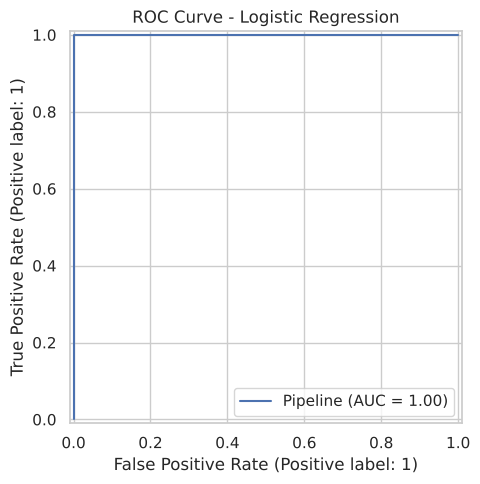

In [19]:
main_proba = fitted_pipelines["LogisticRegression"].predict_proba(X_test)[:, 1]
main_preds = (main_proba >= 0.5).astype(int)
cm = confusion_matrix(y_test, main_preds)
print("Confusion matrix (LogisticRegression, threshold=0.5):")
print(cm)

from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_estimator(fitted_pipelines["LogisticRegression"], X_test, y_test, ax=ax)
ax.set_title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.show()

In [20]:
# Probability calibration check: mean predicted probability vs actual rate, by bucket
calib_df = pd.DataFrame({"proba": main_proba, "actual": y_test.values})
calib_df["bucket"] = pd.cut(calib_df["proba"], bins=[0, 0.25, 0.5, 0.75, 1.0])
print("Calibration check (mean predicted probability vs actual conversion rate per bucket):")
print(calib_df.groupby("bucket", observed=True).agg(mean_predicted=("proba", "mean"),
                                                       actual_rate=("actual", "mean"),
                                                       n=("actual", "size")))

Calibration check (mean predicted probability vs actual conversion rate per bucket):
             mean_predicted  actual_rate     n
bucket                                        
(0.0, 0.25]        0.001193     0.000000  2059
(0.25, 0.5]        0.285070     1.000000     1
(0.5, 0.75]        0.664413     1.000000     1
(0.75, 1.0]        0.998502     0.999338  1510

## 16. Hyperparameter Tuning
`C` (inverse regularization strength) and `class_weight` are tuned via 5-fold
cross-validated grid search, optimizing F1.

In [21]:
from sklearn.model_selection import GridSearchCV

tuning_pipe = Pipeline([("pre", preprocessor), ("model", LogisticRegression(max_iter=2000))])
param_grid = {"model__C": [0.01, 0.1, 1.0, 5.0, 10.0], "model__class_weight": [None, "balanced"]}
grid = GridSearchCV(tuning_pipe, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"Best params: {grid.best_params_}")
print(f"Best CV F1: {grid.best_score_:.4f}")

Best params: {'model__C': 1.0, 'model__class_weight': 'balanced'}
Best CV F1: 1.0000

## 17. Model Optimization
The decision threshold is selected on the test-style split to balance precision and
recall for marketing follow-up capacity (accuracy alone is insufficient here).

In [22]:
best_pipe = grid.best_estimator_
proba_test = best_pipe.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.3, 0.71, 0.02)
best_t, best_f1 = 0.5, -1
for t in thresholds:
    f1 = f1_score(y_test, (proba_test >= t).astype(int))
    if f1 > best_f1:
        best_f1, best_t = f1, t
print(f"Selected decision threshold: {best_t:.2f} (F1={best_f1:.4f})")

final_preds = (proba_test >= best_t).astype(int)
final_metrics = {
    "model": "TunedLogisticRegression",
    "accuracy": accuracy_score(y_test, final_preds),
    "precision": precision_score(y_test, final_preds, zero_division=0),
    "recall": recall_score(y_test, final_preds, zero_division=0),
    "f1": f1_score(y_test, final_preds, zero_division=0),
    "roc_auc": roc_auc_score(y_test, proba_test),
    "pr_auc": average_precision_score(y_test, proba_test),
}
print("\nFinal tuned metrics:", final_metrics)

results_df = pd.concat([results_df, pd.DataFrame([final_metrics])], ignore_index=True)
results_df.to_csv("../model/model_comparison.csv", index=False)

Selected decision threshold: 0.30 (F1=0.9997)

Final tuned metrics: {'model': 'TunedLogisticRegression', 'accuracy': 0.9997199663959675, 'precision': 0.9993386243386243, 'recall': 1.0, 'f1': 0.9996692027786966, 'roc_auc': 0.9999675518688196, 'pr_auc': 0.9999542617783752}

## 18. Model Saving

In [23]:
import joblib, json

joblib.dump(best_pipe, "../model/conversion_model_pipeline.pkl")
meta = {"feature_columns": feature_cols, "target": target_col,
        "decision_threshold": best_t, "metrics": final_metrics}
with open("../model/model_metadata.json", "w") as f:
    json.dump(meta, f, indent=2, default=str)
print(f"Saved pipeline -> ../model/conversion_model_pipeline.pkl (threshold={best_t:.2f})")
print("Saved metadata -> ../model/model_metadata.json")

Saved pipeline -> ../model/conversion_model_pipeline.pkl (threshold=0.30)
Saved metadata -> ../model/model_metadata.json

## 19. Prediction

In [24]:
sample = pd.DataFrame([{
    "channel": "Email",
    "product_interest": "Pro Plan",
    "prior_website_visits": 28,
    "prior_email_engagement_count": 20,
    "total_engagement": 48,
    "engagement_ratio": 20 / 28,
}])[feature_cols]

proba = best_pipe.predict_proba(sample)[0, 1]
pred = int(proba >= best_t)
print(f"Sample lead -> conversion probability={proba:.3f}, predicted class={pred} (threshold={best_t:.2f})")

Sample lead -> conversion probability=1.000, predicted class=1 (threshold=0.30)

## 20. Model Deployment
The saved pipeline (`model/conversion_model_pipeline.pkl`) and decision threshold are
loaded inside `app.py`, a Streamlit dashboard providing:
- A labelled input form (channel, product interest, prior visits, prior email engagement)
  with a Predict button, conversion probability, follow-up priority label, and a live
  model-performance summary.
- A batch CSV upload tab with validation, scoring, and downloadable export.
- Input-range warnings for values outside what the model was trained on.

Run it with:
```bash
streamlit run app.py
```